<a href="https://colab.research.google.com/github/fforster/alerce-iucaa-2026/blob/main/03_supernovae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Supernovae: DELIGHT host galaxies and spectroscopic redshifts

**ALeRCE multisurvey tutorial — IUCAA 2026** · ~35 min

A supernova light curve tells us how bright the explosion *looks*. To know how bright it *is*, we need its
distance, and for most transients the best distance comes from the **redshift of the host galaxy**. In this
notebook we:

1. follow one supernova, **SN 2026gzf**, in ZTF and LSST at the same time;
2. find its host galaxy with **DELIGHT** (Förster et al. 2022), a neural network trained to point from a transient
   to its host using multi-resolution Pan-STARRS images;
3. look up the **spectroscopic redshift** of that host (DESI DR1, NED, SDSS, 2dF… through the experimental explorer)
   and compute the **absolute-magnitude** light curve;
4. repeat the whole chain for a **sample** of 2026 supernovae seen by both surveys, and build a Hubble-diagram-style
   plot, compare the ZTF and LSST classifiers, and ask which survey detects them first.

**Tables used:** `object`, `detection`, `ztf_detection`, `lsst_detection`, `forced_photometry`,
`ztf_forced_photometry`, `lsst_forced_photometry`, `probability`, `classifier`, `taxonomy`, `ztf_ps1`, `xmatch`,
`feature`, `feature_name_lut`, `band`.

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip -q install pyvo astroquery
    !wget -q -N https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/alerce_ms.py
    !mkdir -p data
    !wget -q -N -P data https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/data/sn_sample.csv
    !wget -q -N -P data https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/data/delight_hosts.csv
    !wget -q -N -P data https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/data/sn_hosts.csv

import io
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.cosmology import Planck18

import alerce_ms as am

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

**DELIGHT** is a pip package (`astro-delight`) that needs TensorFlow. Installing it on Colab takes 1–3 minutes.
If you prefer to skip it (or the install fails), set `USE_DELIGHT = False`: the notebook will then read the
host positions that we precomputed with exactly the same code (`data/delight_hosts.csv`).

In [2]:
USE_DELIGHT = True

if USE_DELIGHT and "google.colab" in sys.modules:
    !pip -q install astro-delight

try:
    from delight.delight import Delight
except Exception as e:          # not installed, or TensorFlow problems
    print("DELIGHT not available:", repr(e)[:120], "-> using precomputed host positions")
    USE_DELIGHT = False

I0000 00:00:1793069074.944084 2401142 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793069074.944586 2401142 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793069074.983670 2401142 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793069075.860565 2401142 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793069075.860866 2401142 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Part A · One supernova, two surveys

### A.1 The light curve

`ZTF26aaonmha` was discovered by ZTF in May 2026 and classified spectroscopically on the Transient Name Server as
**SN 2026gzf, a type Ic-BL** (a stripped-envelope supernova with very broad lines, the class associated with
long gamma-ray bursts). It lies in the COSMOS field, which Rubin observes as a *deep drilling field*.
First we find its LSST counterpart with a cone search across both surveys:

In [3]:
ZTF_NAME = "ZTF26aaonmha"
obj = am.get_object(ZTF_NAME, "ztf")
ra, dec = obj["meanra"], obj["meandec"]
twins = am.find_counterparts(ra, dec, radius_arcsec=2)
twins

,name,survey,ra,dec,sid,oid,sep_arcsec
0,ZTF26aaonmha,ztf,149.928671,0.418448,0,36029005852662990,0.000000
1,314003014107006318,lsst,149.928639,0.418435,1,314003014107006318,0.125596


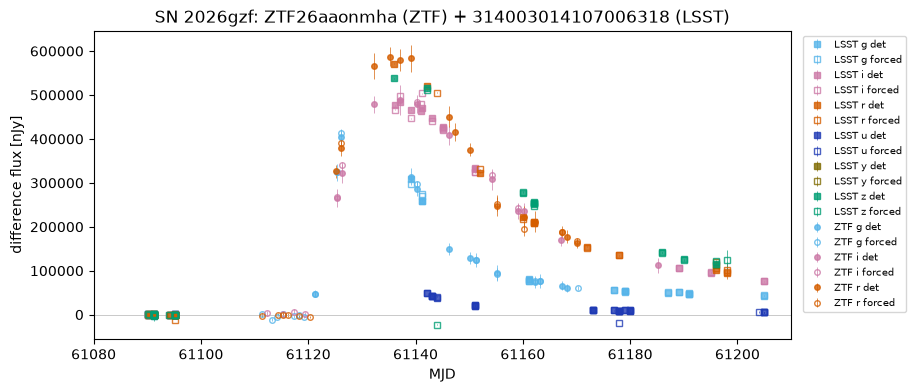

In [4]:
LSST_OID = int(twins.query("survey == 'lsst'").oid.iloc[0])
lc = pd.concat([am.get_lightcurve(ZTF_NAME, sid=0), am.get_lightcurve(LSST_OID, sid=1)])
ax = am.plot_lightcurve(lc, flux="diff", title=f"SN 2026gzf: {ZTF_NAME} (ZTF) + {LSST_OID} (LSST)")
ax.set_xlim(61080, 61210);

The two surveys trace the same rise and decline. LSST adds the $u$, $z$ and $y$ bands and many more epochs.

### A.2 What do the classifiers say?

ZTF has a *light-curve* classifier (it uses the whole light curve, so it improves with time). LSST so far only has
*stamp* classifiers, which look at the image cut-outs of the **first alert** only.

In [5]:
p_ztf = am.get_probabilities(ZTF_NAME, sid=0).query("ranking <= 2")
p_ztf = p_ztf[p_ztf.classifier_name.str.endswith(("_top", "_transient")) | p_ztf.classifier_name.str.startswith("stamp")]
p_lsst = am.get_probabilities(LSST_OID, sid=1).query("ranking <= 2")
pd.concat([p_ztf, p_lsst])[["survey_name", "classifier_name", "class_name", "probability", "ranking", "lastmjd"]]

,survey_name,classifier_name,class_name,probability,ranking,lastmjd
36,ZTF,lc_classifier_BHRF_forced_phot_top,Transient,0.952000,1,61185.211435
37,ZTF,lc_classifier_BHRF_forced_phot_top,Stochastic,0.038000,2,61185.211435
39,ZTF,lc_classifier_BHRF_forced_phot_transient,SESN,0.448000,1,61185.211435
40,ZTF,lc_classifier_BHRF_forced_phot_transient,SNIa,0.216000,2,61185.211435
45,ZTF,stamp_classifier,bogus,0.421051,1,61121.316262
46,ZTF,stamp_classifier,SN,0.385829,2,61121.316262
50,ZTF,stamp_classifier_2025_beta,bogus,0.547614,1,61121.316262
51,ZTF,stamp_classifier_2025_beta,SN,0.308545,2,61121.316262
0,LSST DIA Object,stamp_classifier_rubin_beta,bogus,0.589957,1,61058.299537
1,LSST DIA Object,stamp_classifier_rubin_beta,AGN,0.283899,2,61058.299537


The ZTF light-curve classifier calls it a **Transient** and, inside the transient branch, a **SESN**
(stripped-envelope SN) — correct! The stamp classifiers are much less sure: ZTF's say *bogus* or *SN* (≈0.4 each),
and both Rubin stamp classifiers say *bogus*, with *AGN* a close second. Look at `lastmjd`: for stamp classifiers
it is the time of the **first alert**. For this LSST diaObject that was a noisy detection on the host-galaxy
nucleus about 60 days *before* the explosion (see notebook 01), so the LSST stamp classifier never saw the
supernova — a galaxy nucleus is exactly what an AGN looks like. Lesson: always check which data a classification
is based on.

In [6]:
first_lsst_alert = lc.query("survey == 'lsst' and kind == 'det'").mjd.min()
print(f"first LSST detection: MJD {first_lsst_alert:.2f}; first ZTF detection: MJD {obj['firstmjd']:.2f}")

first LSST detection: MJD 61058.30; first ZTF detection: MJD 61121.32


### A.3 A first hint of the host: Pan-STARRS in the ZTF alerts

Every ZTF alert lists the closest Pan-STARRS1 sources (`ztf_ps1`). `sgscore1` is a star/galaxy score (1 = star,
0 = galaxy) and `distpsnr1` the distance in arcsec:

In [7]:
am.tap_query(f"""
    SELECT TOP 1 objectidps1, sgmag1, srmag1, simag1, sgscore1, distpsnr1
    FROM alerce_tap.ztf_ps1 WHERE oid = {am.ztf_name_to_oid(ZTF_NAME)}
""")

,objectidps1,sgmag1,srmag1,simag1,sgscore1,distpsnr1
0,108501499287012488,19.4995,19.8514,-999.0,0.026833,0.189624


A galaxy (`sgscore1` ≈ 0.03) only 0.2″ away. But "closest PS1 source" is not always the host: for big galaxies the
catalogued centroid can be far, or the closest source can be a different, compact object. That is the problem
DELIGHT solves.

### A.4 DELIGHT: where is the host?

DELIGHT downloads a Pan-STARRS $r$-band image around the transient, builds five images at different resolutions
(a "multi-resolution" stack: the inner 30″ at full resolution, then 2×, 4×, … coarser) and a convolutional network
predicts the vector from the transient to the host centre. It averages the prediction over 8 rotations/flips of the
input, so you also get an uncertainty.

In [8]:
def run_delight(names, ras, decs, datadir="delight_data"):
    """Run DELIGHT on lists of names/coordinates. Returns a DataFrame with ra_delight, dec_delight."""
    d = Delight(datadir, list(names), list(ras), list(decs))
    d.download()                     # Pan-STARRS images from CDS hips2fits
    d.get_pix_coords()
    d.compute_multiresolution(nlevels=5, domask=False, doobject=True, doplot=False)
    d.load_model()
    d.preprocess()
    d.predict()
    out = d.df[["ra_delight", "dec_delight"]].copy()
    out.index.name = "ztf_name"
    return out.reset_index()


precomputed_hosts = pd.read_csv("data/delight_hosts.csv")

if USE_DELIGHT:
    t0 = time.time()
    host = run_delight([ZTF_NAME], [ra], [dec])
    print(f"DELIGHT ran in {time.time() - t0:.1f} s")
else:
    host = precomputed_hosts.query("ztf_name == @ZTF_NAME")

host_ra, host_dec = float(host.ra_delight.iloc[0]), float(host.dec_delight.iloc[0])
offset = am.angular_sep_arcsec(ra, dec, host_ra, host_dec)
print(f"host centre: ({host_ra:.6f}, {host_dec:.6f}), {float(offset):.2f} arcsec from the SN")

Downloaded delight_data/fits/stack_r_ra149.928671_dec0.418448_arcsec120.fits using HiPS2Fits.
Loading WCS information


E0000 00:00:1793069081.963290 2401142 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


DELIGHT ran in 5.6 s
host centre: (149.929044, 0.417670), 3.11 arcsec from the SN


Let us look at the Pan-STARRS colour image (from the CDS `hips2fits` service) with the supernova and the
DELIGHT host marked:

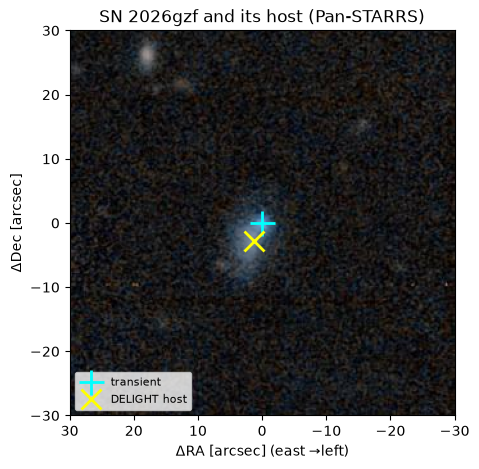

In [9]:
def ps1_image(ra, dec, fov_arcsec=60, npix=300):
    """Pan-STARRS colour cut-out (north up, east left) from CDS hips2fits."""
    url = "https://alasky.cds.unistra.fr/hips-image-services/hips2fits"
    params = dict(hips="CDS/P/PanSTARRS/DR1/color-z-zg-g", width=npix, height=npix,
                  fov=fov_arcsec / 3600, ra=ra, dec=dec, projection="TAN", format="jpg")
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    return plt.imread(io.BytesIO(r.content), format="jpg")


def sky_to_offsets(ra0, dec0, ra, dec):
    """Offsets in arcsec (east, north) of (ra, dec) from (ra0, dec0)."""
    dx = (np.asarray(ra) - ra0) * np.cos(np.radians(dec0)) * 3600
    dy = (np.asarray(dec) - dec0) * 3600
    return dx, dy


def show_host(ra, dec, host_ra, host_dec, title="", fov=60, others=None):
    img = ps1_image(ra, dec, fov)
    fig, ax = plt.subplots(figsize=(5, 5))
    half = fov / 2
    ax.imshow(img, extent=[half, -half, -half, half], origin="upper")   # east to the left
    ax.plot(0, 0, "+", color="cyan", ms=18, mew=2, label="transient")
    hx, hy = sky_to_offsets(ra, dec, host_ra, host_dec)
    ax.plot(hx, hy, "x", color="yellow", ms=14, mew=2, label="DELIGHT host")
    if others is not None:
        ox, oy = sky_to_offsets(ra, dec, others.ra, others.dec)
        ax.plot(ox, oy, "o", mfc="none", color="lime", ms=10, label="spec-z")
    ax.set_xlabel("ΔRA [arcsec] (east →left)")
    ax.set_ylabel("ΔDec [arcsec]")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower left")
    return ax


show_host(ra, dec, host_ra, host_dec, title="SN 2026gzf and its host (Pan-STARRS)");

### A.5 The redshift of the host

The experimental explorer queries more than a dozen redshift catalogs (Simbad, NED, SDSS, DESI DR1, 2dF, 6dF,
GAMA, 2MRS, GLADE, HECATE, …) and labels each match as `stellar`, `agn` or `host`. One call:

In [10]:
xm = am.explorer_xmatch(ZTF_NAME, "ztf")
hosts_xm = xm[(xm.category == "host") & xm.z.notna()].copy()
hosts_xm["sep_from_delight"] = am.angular_sep_arcsec(host_ra, host_dec, hosts_xm.ra, hosts_xm.dec)
hosts_xm[["cat_name", "name", "type", "z", "z_err", "sep", "sep_from_delight"]]

,cat_name,name,type,z,z_err,sep,sep_from_delight
3,NED,SDSS J095942.88+002506.2,G,0.034514,0.000297,0.178264,2.955510
4,Simbad,2dFGRS TGN352Z077,Galaxy,0.034500,NaN,0.199212,2.931369
6,2dFGRS,2dFGRS J095942.9+002503.9,NaN,0.034500,NaN,2.613759,0.689155
7,HECATE,PGC1165398,NaN,0.034510,0.000166,3.337126,0.672954
8,GLADE v2,GLADE v2 J095943.0+002503.2,G,0.034407,NaN,3.443662,0.458238
9,DESI,DESI J149.9299+00.4181,GALAXY,0.034328,0.000006,4.680830,3.759828
10,DESI,DESI J149.9227+00.4165,GALAXY,0.882609,0.000024,22.520350,23.152872


Every catalog agrees on **z ≈ 0.0345** for the galaxy at the DELIGHT position (the one at z = 0.88 is an unrelated
background galaxy 22″ away). You can also query the catalogs yourself. Here is DESI DR1 through VizieR and NED
through its TAP service:

In [11]:
from astroquery.vizier import Vizier
import pyvo

host_coord = SkyCoord(host_ra, host_dec, unit="deg")
desi = Vizier(columns=["**", "_r"], row_limit=20).query_region(host_coord, radius=5 * u.arcsec,
                                                                catalog="V/161/zcatdr1")
desi = desi[0].to_pandas()[["_r", "RAICRS", "DEICRS", "z", "e_z", "ZWARN", "OType"]] if len(desi) else None
desi

/home/fforster/.claude/jobs/0cdd4c46/tmp/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:2611: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)


,_r,RAICRS,DEICRS,z,e_z,ZWARN,OType
0,3.749,149.929947,0.418195,0.034328,0.000006,0,GALAXY


In [12]:
ned = pyvo.dal.TAPService("https://ned.ipac.caltech.edu/tap")
ned.search(f"""
    SELECT prefname, ra, dec, z, zflag, prefphytype
    FROM NEDTAP.objdir
    WHERE 1 = CONTAINS(POINT('J2000', ra, dec), CIRCLE('J2000', {host_ra}, {host_dec}, {5 / 3600}))
      AND z IS NOT NULL
""").to_table().to_pandas()

,prefname,ra,dec,z,zflag,prefphytype
0,SN 2026gzf,149.928633,0.418439,0.034400,IUN,SN
1,SDSS J095942.88+002506.2,149.928667,0.418399,0.034514,SUN,G


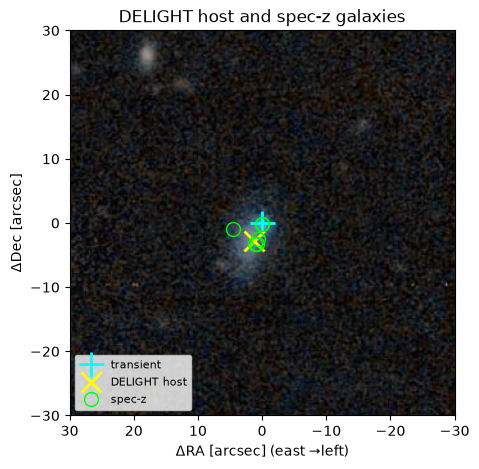

In [13]:
show_host(ra, dec, host_ra, host_dec, title="DELIGHT host and spec-z galaxies",
          others=hosts_xm[hosts_xm.sep < 15]);

### A.6 Absolute magnitudes

With $z$ we get the luminosity distance $d_L$ (Planck 2018 cosmology) and the distance modulus
$\mu = 5\log_{10}(d_L / 10\,\mathrm{pc})$. The absolute magnitude is $M = m - \mu$
(we ignore Milky-Way extinction and the K-correction, both small here — see the exercises).

z = 0.03433  ->  d_L = 156.1 Mpc,  mu = 35.97 mag


,survey,band_name,mjd,diff_mag,M
138,lsst,g,61139.07,17.67,-18.29
148,lsst,i,61141.17,17.14,-18.82
132,lsst,r,61136.02,17.01,-18.96
150,lsst,u,61142.07,19.67,-16.30
243,lsst,y,61196.04,18.70,-17.27
133,lsst,z,61136.02,17.07,-18.89
27,ztf,g,61126.19,17.36,-18.61
33,ztf,i,61137.16,17.18,-18.79
32,ztf,r,61135.17,16.98,-18.99


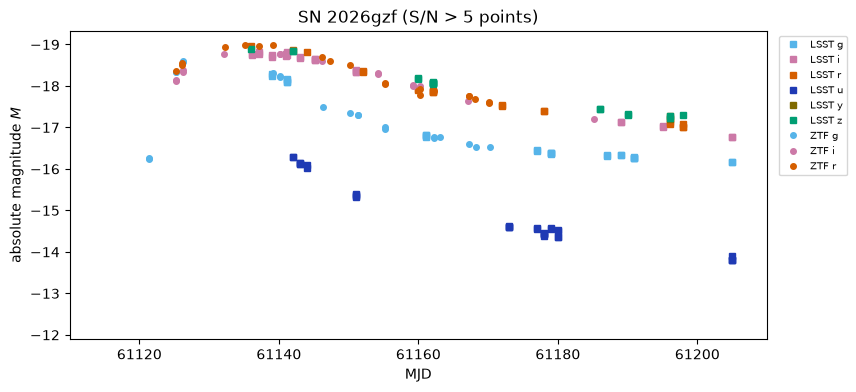

In [14]:
z_host = float(desi.z.iloc[0]) if desi is not None else float(hosts_xm.z.median())
mu = Planck18.distmod(z_host).value
print(f"z = {z_host:.5f}  ->  d_L = {Planck18.luminosity_distance(z_host):.1f},  mu = {mu:.2f} mag")

good = lc[(lc.diff_flux / lc.diff_flux_err > 5)].copy()
good["M"] = good.diff_mag - mu
fig, ax = plt.subplots(figsize=(9, 4))
for (survey, band), g in good.groupby(["survey", "band_name"]):
    ax.plot(g.mjd, g.M, am.SURVEY_MARKERS[survey], color=am.BAND_COLORS[band], ms=4, label=f"{survey.upper()} {band}")
ax.invert_yaxis()
ax.set_xlim(61110, 61210)
ax.set_xlabel("MJD")
ax.set_ylabel("absolute magnitude $M$")
ax.set_title("SN 2026gzf (S/N > 5 points)")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
peak = good.loc[good.groupby(["survey", "band_name"]).M.idxmin(), ["survey", "band_name", "mjd", "diff_mag", "M"]]
peak.round(2)

The peak is $M_r \approx -19$, consistent between ZTF and LSST. SNe Ic-BL are typically brighter than ordinary
stripped-envelope SNe ($M \approx -17.5$) and peak around $M \approx -18.5$ to $-19$, not far from SNe Ia
($M \approx -19.3$), so SN 2026gzf is on the bright side of its class.

## Part B · A sample of supernovae seen by ZTF and LSST

### B.1 Building the sample

We want 2026 supernova candidates from the ZTF light-curve classifier (transient branch: `SNIa`, `SNII`, `SESN`)
that also have an LSST counterpart. The recipe:

1. page through candidates with the API's `list_objects` (it filters on classifier, class, probability and dates
   using database indexes, so it is fast);
2. for each candidate, run `find_counterparts` and keep those with an LSST object within 2″.

Step 2 makes one request per candidate (~600 requests), too many for a classroom sharing one IP address. So the
result is saved in `data/sn_sample.csv`; set `REBUILD = True` to run it yourself at home.

In [15]:
REBUILD = False


def ztf_sn_candidates(class_name, min_prob=0.4, mjd_range=(61000, 61400), pages=3):
    rows = []
    for page in range(1, pages + 1):
        d = am.api_get("object", "list_objects", survey="ztf",
                       classifier="lc_classifier_BHRF_forced_phot_transient", class_name=class_name,
                       probability=min_prob, firstmjd=list(mjd_range), page=page, page_size=100)
        rows += d["items"]
        if not d["has_next"]:
            break
    return pd.DataFrame(rows).drop_duplicates("oid")


def with_lsst_counterpart(cands, radius_arcsec=2.0, pause=1.0):
    out = []
    for r in cands.itertuples():
        c = am.find_counterparts(r.meanra, r.meandec, radius_arcsec)
        time.sleep(pause)                           # be gentle with the server
        c = c[c.survey == "lsst"] if len(c) else c
        if len(c):
            out.append(dict(ztf_name=r.oid, lsst_oid=int(c.oid.iloc[0]), sep=c.sep_arcsec.iloc[0],
                            ztf_class=r.class_name, ztf_prob=r.probability, ra=r.meanra, dec=r.meandec,
                            firstmjd=r.firstmjd, n_det=r.n_det))
    return pd.DataFrame(out)


if REBUILD:
    sample = pd.concat([with_lsst_counterpart(ztf_sn_candidates(c)) for c in ("SNIa", "SNII", "SESN")])
else:
    sample = pd.read_csv("data/sn_sample.csv")

print(len(sample), "ZTF supernova candidates with an LSST counterpart")
sample.groupby("ztf_class").size()

20 ZTF supernova candidates with an LSST counterpart


ztf_class
SESN     3
SNII    10
SNIa     7
dtype: int64

Only a few percent of the ZTF candidates have an LSST twin: ZTF observes the northern sky down to
Dec ≈ −30°, Rubin the southern sky, and in 2026 Rubin had not yet covered its whole footprint. Where are they?

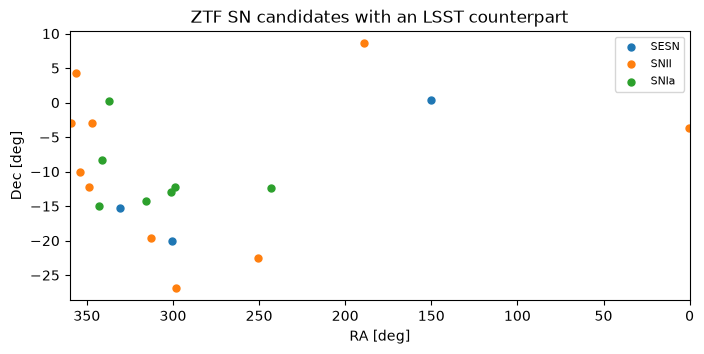

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for cls, g in sample.groupby("ztf_class"):
    ax.scatter(g.ra, g.dec, s=25, label=cls)
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_xlim(360, 0)
ax.legend(fontsize=8)
ax.set_title("ZTF SN candidates with an LSST counterpart");

### B.2 Batch queries: one query for many objects

Instead of one query per object, we send the whole list with `oid IN (...)`. This is much faster and much kinder to
the server.

In [17]:
ztf_oids = [am.ztf_name_to_oid(n) for n in sample.ztf_name]
lsst_oids = [int(o) for o in sample.lsst_oid]
name_of = dict(zip(ztf_oids, sample.ztf_name)) | dict(zip(lsst_oids, sample.ztf_name))


def in_list(values):
    return ", ".join(str(int(v)) for v in values)


def batch_lightcurves(oids, sid):
    """Detections + forced photometry of many objects, as signed difference fluxes in nJy."""
    parts = []
    for common, kind in [("detection", "det"), ("forced_photometry", "forced")]:
        if sid == 0:
            ext, mag, err = ("ztf_detection", "magpsf", "sigmapsf") if kind == "det" \
                else ("ztf_forced_photometry", "mag", "e_mag")
            df = am.tap_query(f"""
                SELECT c.oid, c.mjd, c.band, x.{mag} AS mag, x.{err} AS e_mag, x.isdiffpos
                FROM alerce_tap.{common} AS c
                JOIN alerce_tap.{ext} AS x ON x.oid = c.oid AND x.measurement_id = c.measurement_id
                WHERE c.sid = 0 AND c.oid IN ({in_list(oids)})""")
            df.loc[df.e_mag >= 100, "e_mag"] = np.nan
            df["flux"] = np.where(df.isdiffpos < 0, -1, 1) * am.mag_to_flux(df.mag)
            df["flux_err"] = 0.4 * np.log(10) * df.flux.abs() * df.e_mag
        else:
            ext = "lsst_detection" if kind == "det" else "lsst_forced_photometry"
            df = am.tap_query(f"""
                SELECT c.oid, c.mjd, c.band, x.psfflux AS flux, x.psffluxerr AS flux_err
                FROM alerce_tap.{common} AS c
                JOIN alerce_tap.{ext} AS x
                  ON x.oid = c.oid AND x.measurement_id = c.measurement_id AND x.sid = c.sid
                WHERE c.sid = 1 AND c.oid IN ({in_list(oids)})""")
        parts.append(df.assign(kind=kind))
    df = pd.concat(parts, ignore_index=True)
    df["sid"] = sid
    df["survey"] = am.SURVEY[sid]
    df["band_name"] = [am.band_label(sid, b) for b in df.band]
    df["ztf_name"] = df.oid.map(name_of)
    return df[np.isfinite(df.flux_err) & (df.flux_err > 0)]


phot = pd.concat([batch_lightcurves(ztf_oids, 0), batch_lightcurves(lsst_oids, 1)], ignore_index=True)
print(len(phot), "photometric points for", phot.ztf_name.nunique(), "supernovae (4 TAP queries in total)")
phot.groupby(["survey", "kind", "band_name"]).size().unstack([0, 1])

2789 photometric points for 20 supernovae (4 TAP queries in total)


survey     lsst           ztf       
kind        det forced    det forced
band_name                           
g          41.0   37.0  296.0  507.0
i          59.0   65.0  195.0  388.0
r          35.0   39.0  480.0  534.0
u          16.0   19.0    NaN    NaN
y           1.0    2.0    NaN    NaN
z          30.0   45.0    NaN    NaN

### B.3 Host galaxies and redshifts for the whole sample

DELIGHT processes a whole list in one call (it is fast once the images are downloaded). Then we look for a
spectroscopic redshift within 3″ of each DELIGHT host.

⚠️ Be careful with *compilations*: GLADE, HECATE, NED and Simbad mix spectroscopic and **photometric** redshifts
(NED tells you which in its `zflag` column: `S…` = spectroscopic, `P…` = photometric). We therefore accept, in order:
(1) purely spectroscopic surveys (DESI, SDSS, 2dF, 6dF, 2MRS, …) from the explorer, (2) NED redshifts with
`zflag` starting with `S`, (3) as a last resort, the redshift of the supernova **itself** measured from its
classification spectrum (labelled `transient`; less precise, often rounded to 0.01).

Running this live means ~20 image downloads and ~20 explorer + NED queries, so by default we read the
precomputed result.

In [18]:
RUN_SAMPLE_DELIGHT = False   # True: run DELIGHT on all objects (needs USE_DELIGHT, ~1 min)

if USE_DELIGHT and RUN_SAMPLE_DELIGHT:
    hosts = run_delight(sample.ztf_name, sample.ra, sample.dec)
else:
    hosts = precomputed_hosts[["ztf_name", "ra_delight", "dec_delight"]]
hosts = hosts.merge(sample[["ztf_name", "ra", "dec"]], on="ztf_name")
hosts["offset_arcsec"] = am.angular_sep_arcsec(hosts.ra, hosts.dec, hosts.ra_delight, hosts.dec_delight)
hosts.describe().loc[["count", "mean", "50%", "max"], ["offset_arcsec"]]

,offset_arcsec
count,20.000000
mean,5.607367
50%,4.879613
max,13.195826


In [19]:
SPEC_SURVEYS = {"DESI", "SDSS", "2dFGRS", "6dFGS", "GAMA", "2MRS", "WiggleZ", "zCOSMOS", "VIPERS", "OzDES"}


def host_redshift(name, host_ra, host_dec, radius=3.0):
    """Spectroscopic redshift closest to the host position (within ``radius`` arcsec).

    1. purely spectroscopic surveys returned by the experimental explorer (DESI, SDSS, 2dF, 6dF, ...);
    2. NED, keeping only redshifts flagged as spectroscopic (zflag starting with 'S');
    3. otherwise the redshift of the *transient itself* from its classification spectrum (NED type SN).
    """
    x = am.explorer_xmatch(name, "ztf")
    if len(x):
        x = x[x.cat_name.isin(SPEC_SURVEYS) & x.z.notna()].copy()
        x["d"] = am.angular_sep_arcsec(host_ra, host_dec, x.ra, x.dec)
        x = x[x.d < radius].sort_values("d")
        if len(x):
            return dict(z=x.z.iloc[0], z_kind="host", z_source=x.cat_name.iloc[0],
                        z_name=str(x["name"].iloc[0]), z_sep=x.d.iloc[0])
    n = ned.search(f"""
        SELECT prefname, ra, dec, z, zflag, prefphytype FROM NEDTAP.objdir
        WHERE 1 = CONTAINS(POINT('J2000', ra, dec), CIRCLE('J2000', {host_ra}, {host_dec}, {radius / 3600}))
          AND z IS NOT NULL""").to_table().to_pandas()
    if len(n):
        n["d"] = am.angular_sep_arcsec(host_ra, host_dec, n.ra, n.dec)
        n = n.sort_values("d")
        spec = n[n.zflag.astype(str).str.startswith("S") & (n.prefphytype != "SN")]
        if len(spec):
            return dict(z=spec.z.iloc[0], z_kind="host", z_source="NED (zflag " + spec.zflag.iloc[0] + ")",
                        z_name=spec.prefname.iloc[0], z_sep=spec.d.iloc[0])
        sn = n[n.prefphytype == "SN"]
        if len(sn):
            return dict(z=sn.z.iloc[0], z_kind="transient", z_source="NED (SN spectrum)",
                        z_name=sn.prefname.iloc[0], z_sep=sn.d.iloc[0])
    return dict(z=np.nan, z_kind="", z_source="", z_name="", z_sep=np.nan)


if REBUILD:
    zs = []
    for r in hosts.itertuples():
        zs.append(dict(ztf_name=r.ztf_name, **host_redshift(r.ztf_name, r.ra_delight, r.dec_delight)))
        time.sleep(1)
    zs = pd.DataFrame(zs)
else:
    zs = pd.read_csv("data/sn_hosts.csv")

hosts = hosts.merge(zs, on="ztf_name", how="left")
print(hosts.z_kind.value_counts().to_string())
hosts.merge(sample[["ztf_name", "ztf_class"]])[
    ["ztf_name", "ztf_class", "offset_arcsec", "z", "z_kind", "z_source", "z_name", "z_sep"]].round(4)

z_kind
host         10
transient     6


,ztf_name,ztf_class,offset_arcsec,z,z_kind,z_source,z_name,z_sep
0,ZTF26abfgmuh,SESN,1.0573,0.0820,transient,NED (SN spectrum),SN 2026qfo,1.203
1,ZTF26abbuilh,SESN,10.9596,0.0418,host,6dFGS,6dFGS J200117.9-200602.0,0.294
2,ZTF26aaonmha,SESN,3.1078,0.0345,host,2dFGRS,2dFGRS J095942.9+002503.9,0.689
3,ZTF26aawfokc,SNII,10.7440,0.0348,host,SDSS,1237661977085804649,1.364
4,ZTF26abcynur,SNII,13.1958,NaN,NaN,NaN,NaN,NaN
5,ZTF26abecuvq,SNII,0.7251,0.0700,transient,NED (SN spectrum),SN 2026qif,0.694
6,ZTF25acfxvcu,SNII,4.2936,0.0215,host,2MRS,2MRS J000234.8-034238.6,1.643
7,ZTF26aausykz,SNII,5.9060,0.0388,host,6dFGS,6dFGS J204959.1-193755.1,1.895
8,ZTF26abcbpbm,SNII,9.7424,0.0532,host,DESI,DESI J356.2418+04.3136,0.219
9,ZTF25acazvii,SNII,11.3523,0.0236,host,NED (zflag SUN),MCG -01-01-008,2.886


### B.4 Peak magnitudes and a Hubble diagram

For each supernova and survey we take the brightest $r$-band point (detection or forced photometry) with S/N > 5
as the (approximate) peak, and plot it against the redshift. Lines show where objects of fixed absolute magnitude
would fall.

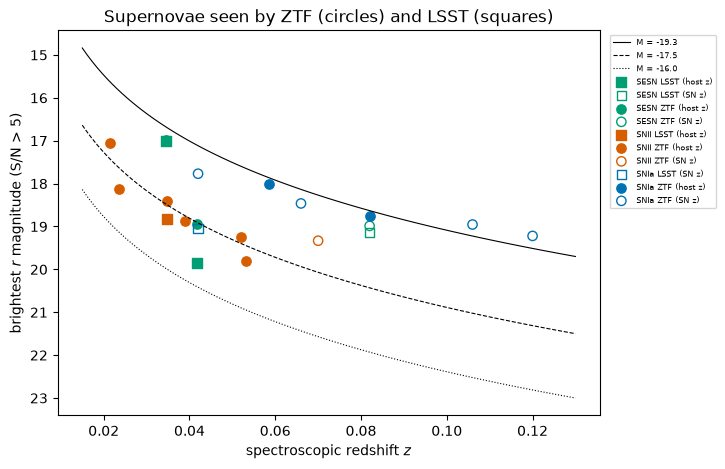

In [20]:
ph_r = phot[(phot.band_name == "r") & (phot.flux / phot.flux_err > 5)]
peaks = (ph_r.loc[ph_r.groupby(["ztf_name", "survey"]).flux.idxmax(), ["ztf_name", "survey", "mjd", "flux"]]
         .assign(peak_mag=lambda d: am.flux_to_mag(d.flux)))
peaks = peaks.merge(hosts[["ztf_name", "z", "z_kind"]], on="ztf_name").merge(
    sample[["ztf_name", "ztf_class"]], on="ztf_name")
peaks = peaks.dropna(subset=["z"])
peaks["M_peak"] = peaks.peak_mag - Planck18.distmod(peaks.z.values).value

fig, ax = plt.subplots(figsize=(7, 5))
zgrid = np.linspace(0.015, 0.13, 100)
for M, ls in [(-19.3, "-"), (-17.5, "--"), (-16.0, ":")]:
    ax.plot(zgrid, M + Planck18.distmod(zgrid).value, "k", ls=ls, lw=0.8, label=f"M = {M}")
markers = {"ztf": "o", "lsst": "s"}
cls_colors = {"SNIa": "#0072b2", "SNII": "#d55e00", "SESN": "#009e73"}
for (cls, survey, kind), g in peaks.groupby(["ztf_class", "survey", "z_kind"]):
    filled = kind == "host"
    ax.scatter(g.z, g.peak_mag, marker=markers[survey], s=45, edgecolors=cls_colors[cls],
               facecolors=cls_colors[cls] if filled else "none",
               label=f"{cls} {survey.upper()} ({'host z' if filled else 'SN z'})")
ax.invert_yaxis()
ax.set_xlabel("spectroscopic redshift $z$")
ax.set_ylabel("brightest $r$ magnitude (S/N > 5)")
ax.legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Supernovae seen by ZTF (circles) and LSST (squares)");

In [21]:
peaks.pivot_table(index=["ztf_name", "ztf_class", "z_kind", "z"], columns="survey", values="M_peak").round(2)

,,,survey,lsst,ztf
ztf_name,ztf_class,z_kind,z,,
ZTF25acazvii,SNII,host,0.023563,NaN,-17.00
ZTF25acfxvcu,SNII,host,0.021498,NaN,-17.87
ZTF26aaonmha,SESN,host,0.034500,-18.97,-19.00
ZTF26aaumtdl,SNIa,transient,0.042000,-17.38,-18.65
ZTF26aausykz,SNII,host,0.038847,NaN,-17.38
ZTF26aawfokc,SNII,host,0.034790,-17.16,-17.60
ZTF26aawxsoy,SNII,host,0.052053,NaN,-17.64
ZTF26aaxninc,SNIa,transient,0.066000,NaN,-18.97
ZTF26aayszgp,SNIa,transient,0.120000,NaN,-19.59


The two SNe Ia with host redshifts peak at $M_r \approx -19.2$, as expected for SNe Ia, while the SNe II with host
redshifts lie between $-17$ and $-17.9$, about 1.5–2 mag fainter. Many LSST entries are missing: in 2026 most of
these fields were visited by Rubin only a few times, so few LSST $r$-band points reach S/N > 5 near peak.
(These are rough numbers: no K-correction, no extinction, and the brightest observed point is not always the
true peak.)

### B.5 Do ZTF and LSST classifiers agree?

For the LSST counterparts we take the top class of the newest Rubin stamp classifier — again in one query.

In [22]:
cid = am.classifier_id("stamp_classifier_rubin_beta_20260421")
lsst_top = am.decode(am.tap_query(f"""
    SELECT oid, sid, classifier_id, class_id, probability, lastmjd
    FROM alerce_tap.probability
    WHERE sid = 1 AND classifier_id = {cid} AND ranking = 1 AND oid IN ({in_list(lsst_oids)})"""))
lsst_top["ztf_name"] = lsst_top.oid.map(name_of)
cmp = sample.merge(lsst_top[["ztf_name", "class_name", "probability"]], on="ztf_name", how="left")
pd.crosstab(cmp.ztf_class, cmp.class_name.fillna("none"), rownames=["ZTF light curve"],
            colnames=["LSST stamp (top class)"])

LSST stamp (top class),SN,asteroid,bogus
ZTF light curve,,,
SESN,1,1,1
SNII,5,5,0
SNIa,5,2,0


About half of the LSST counterparts are called *SN* by the Rubin stamp classifier, but many are called
*asteroid*. The stamp classifier sees a single image triplet: a new point source with no obvious host underneath
looks very much like a moving object. This is a *beta* model, and one reason ALeRCE combines stamp and light-curve
information.

### B.6 Who sees them first?

For each pair, the first epoch with a ≥5σ positive difference flux (detection or forced photometry), per survey:

count     20.0
mean      32.1
std       63.6
min      -63.0
25%        7.4
50%       17.8
75%       29.6
max      204.3
Name: lsst_minus_ztf_days, dtype: float64


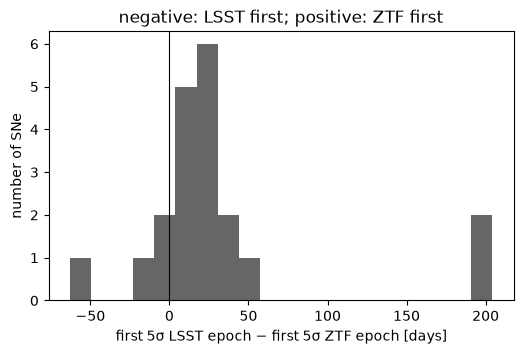

In [23]:
det5 = phot[phot.flux / phot.flux_err > 5]
first = det5.groupby(["ztf_name", "survey"]).mjd.min().unstack()
first["lsst_minus_ztf_days"] = first.lsst - first.ztf
print(first.lsst_minus_ztf_days.describe().round(1))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(first.lsst_minus_ztf_days.dropna(), bins=20, color="0.4")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("first 5σ LSST epoch − first 5σ ZTF epoch [days]")
ax.set_ylabel("number of SNe")
ax.set_title("negative: LSST first; positive: ZTF first");

In [24]:
first.sort_values("lsst_minus_ztf_days").head(3).round(1)

survey,lsst,ztf,lsst_minus_ztf_days
ztf_name,,,
ZTF26aaonmha,61058.3,61121.3,-63.0
ZTF26abfgmuh,61217.4,61227.4,-10.0
ZTF26abfqesy,61221.4,61229.4,-8.0


For most pairs ZTF had a 5σ point first (median ≈ 18 days earlier): in 2026 Rubin revisited most of these fields
only every few weeks, while ZTF observes them every ~2 nights. The most negative value is SN 2026gzf, whose LSST
diaObject had noisy ≥5σ points on the host galaxy long *before* the explosion — the same caveat as in Part A.

Remember also that this sample was **selected by ZTF**, so it is biased towards objects bright enough for ZTF.
How deep does each survey go? Compare the median and the faint end (95th percentile) of the magnitudes of all
5σ points in each survey and band:

In [25]:
det5.assign(mag=am.flux_to_mag(det5.flux)).groupby(["survey", "band_name"]).mag.quantile([0.5, 0.95]).unstack().round(2)

0.50   0.95
survey band_name              
lsst   g          19.59  23.31
       i          19.53  21.46
       r          18.86  21.02
       u          21.39  22.16
       y          18.73  18.75
       z          19.20  20.84
ztf    g          19.45  20.50
       i          19.41  20.21
       r          19.27  20.29

The medians are similar (the same bright supernovae), but the faint end tells the story: LSST 5σ points reach
$g \approx 23$ and $r \approx 21$ while ZTF stops at $\approx 20.2$–$20.5$. Even in short single visits Rubin goes
1–3 magnitudes deeper, so it follows these supernovae much longer on the decline.

### B.7 Crossmatches and PS1 for the sample

Two quick checks with tables we have not used yet in this notebook:

* does the `xmatch` table (AllWISE, Gaia DR3 at the transient position) have counterparts for our SNe? A match at
  the SN position is usually the host *nucleus* — or a sign the "SN" is really a nuclear transient or AGN;
* how does the PS1 distance from the ZTF alert compare with the DELIGHT host offset?

In [26]:
xm_sample = am.tap_query(f"""
    SELECT x.oid, x.sid, x.catid, x.dist FROM alerce_tap.xmatch AS x
    WHERE x.sid = 0 AND x.oid IN ({in_list(ztf_oids)})""").pipe(am.decode)
xm_sample["ztf_name"] = xm_sample.oid.map(name_of)
xm_sample[["ztf_name", "catalog_name", "dist"]].merge(sample[["ztf_name", "ztf_class"]])

,ztf_name,catalog_name,dist,ztf_class
0,ZTF26aaumtdl,AllWISE,0.883176,SNIa


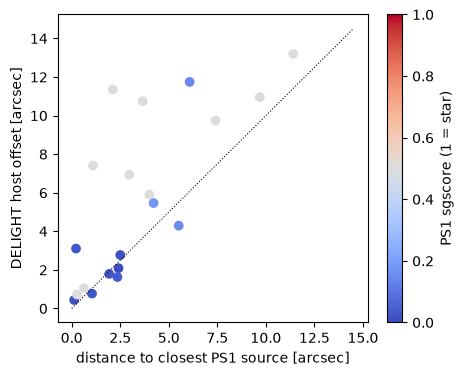

In [27]:
ps1 = am.tap_query(f"""
    SELECT oid, sgscore1, distpsnr1 FROM alerce_tap.ztf_ps1
    WHERE oid IN ({in_list(ztf_oids)})""")
ps1 = ps1[ps1.distpsnr1 >= 0].groupby("oid").median().reset_index()
ps1["ztf_name"] = ps1.oid.map(name_of)
both = ps1.merge(hosts[["ztf_name", "offset_arcsec"]], on="ztf_name")
fig, ax = plt.subplots(figsize=(5, 4))
sc = ax.scatter(both.distpsnr1, both.offset_arcsec, c=both.sgscore1, cmap="coolwarm", vmin=0, vmax=1)
lim = max(both.distpsnr1.max(), both.offset_arcsec.max()) * 1.1
ax.plot([0, lim], [0, lim], "k:", lw=0.8)
ax.set_xlabel("distance to closest PS1 source [arcsec]")
ax.set_ylabel("DELIGHT host offset [arcsec]")
plt.colorbar(sc, label="PS1 sgscore (1 = star)");

Points on the diagonal: the closest PS1 source is the DELIGHT host. When that source is clearly a galaxy (blue)
the two methods usually agree. The big disagreements (points well above the diagonal) mostly involve closest PS1
sources with `sgscore` ≈ 0.5, i.e. faint, ambiguous sources: there DELIGHT points instead to a larger galaxy
5–13″ away, which the closest-source heuristic would have missed. Use the image function `show_host` above to check
a few of them by eye.

## ✏️ Exercises

1. **(easy)** Pick another supernova from `sample` and repeat Part A for it (light curve in both surveys, DELIGHT
   host image, host redshift, absolute magnitude).
2. **(easy)** Correct the peak absolute magnitude of SN 2026gzf for Milky-Way extinction: get $E(B-V)$ with
   `from astroquery.ipac.irsa.irsa_dust import IrsaDust; IrsaDust.get_query_table(coord, section="ebv")` and use
   $A_r = 2.285\,E(B-V)$ (Schlafly & Finkbeiner 2011).
3. **(medium)** The `feature` table contains the parameters of a supernova model fit (`SPM_tau_rise`,
   `SPM_tau_fall`, …) for ZTF *and* LSST. For the pairs in `sample`, compare the rise times measured in each survey.
   Do SNe II rise faster than SNe Ia?
4. **(medium)** Make the Hubble-diagram plot using only SNe Ia and estimate their mean peak absolute magnitude
   and scatter. Which survey gives the smaller scatter? Why?
5. **(challenge)** Assume all SNe Ia have $M_r = -19.3$ at peak and fit the Hubble constant $H_0$ from
   $\mu = m - M$ and $d_L \approx cz/H_0$ (valid for $z \ll 1$). How sensitive is your answer to the assumed $M$?

In [28]:
# your code here

**Next:** [04 · AGN](04_agn.ipynb)